# Effective Detection of Credit Card Fraud Using Machine Learning Techniques

### A Comparative Study of Logistic Regression, Decision Tree, Random Forest, Balanced Random Forest and XGBoost

**Machine Learning Mini Project**

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-test split and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Imbalanced learning
from imblearn.over_sampling import SMOTE
from imblearn.ensemble import BalancedRandomForestClassifier

# XGBoost
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

ModuleNotFoundError: No module named 'seaborn'

In [2]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-test split and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Imbalanced learning
from imblearn.over_sampling import SMOTE
from imblearn.ensemble import BalancedRandomForestClassifier

# XGBoost
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")


ModuleNotFoundError: No module named 'sklearn'

In [3]:
%pip install seaborn scikit-learn imbalanced-learn xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Train-test split and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Imbalanced learning
from imblearn.over_sampling import SMOTE
from imblearn.ensemble import BalancedRandomForestClassifier

# XGBoost
from xgboost import XGBClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Load dataset
df = pd.read_csv("creditcard.csv")

# Display first five rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Dataset Shape:",df.shape)

Dataset Shape: (284807, 31)


In [5]:
# Load dataset
df = pd.read_csv("creditcard.csv")

# Display first five rows
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
print("Columns in the dataset:\n")

for column in df.columns:
    print(column)

Columns in the dataset:

Time
V1
V2
V3
V4
V5
V6
V7
V8
V9
V10
V11
V12
V13
V14
V15
V16
V17
V18
V19
V20
V21
V22
V23
V24
V25
V26
V27
V28
Amount
Class


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [8]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## 3. Data Quality Check

Before training the models, the dataset is checked for missing values and duplicate records.

In [9]:
missing_values=df.isnull().sum()
print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [10]:
duplicate_count=df.duplicated().sum()
print("Duplicated rows:",duplicate_count)

Duplicated rows: 1081


In [11]:
df[df.duplicated()].head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


In [12]:
df = df.drop_duplicates().reset_index(drop=True)

In [13]:
print(df.shape)

(283726, 31)


In [15]:
class_counts = df["Class"].value_counts()

print(class_counts)

Class
0    283253
1       473
Name: count, dtype: int64


In [16]:
class_percentage = df["Class"].value_counts(normalize=True) * 100

print(class_percentage)

Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


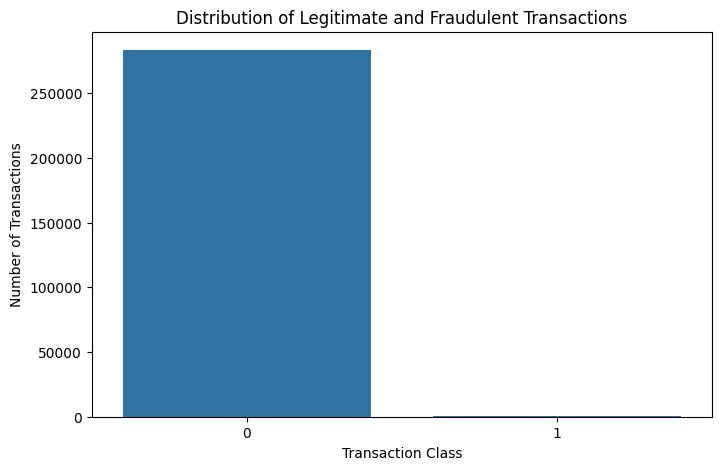

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class"
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

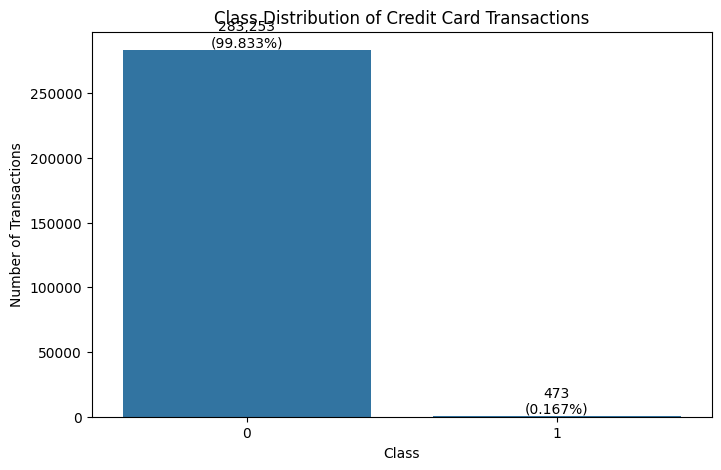

In [19]:
class_counts = df["Class"].value_counts()

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Class Distribution of Credit Card Transactions")
plt.xlabel("Class")
plt.ylabel("Number of Transactions")

for i, value in enumerate(class_counts.values):
    percentage = value / len(df) * 100
    ax.text(
        i,
        value,
        f"{value:,}\n({percentage:.3f}%)",
        ha="center",
        va="bottom"
    )

plt.show()

## 4. Exploratory Data Analysis

The transaction amount is analyzed to understand whether fraudulent and legitimate transactions exhibit different distributions.

In [20]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


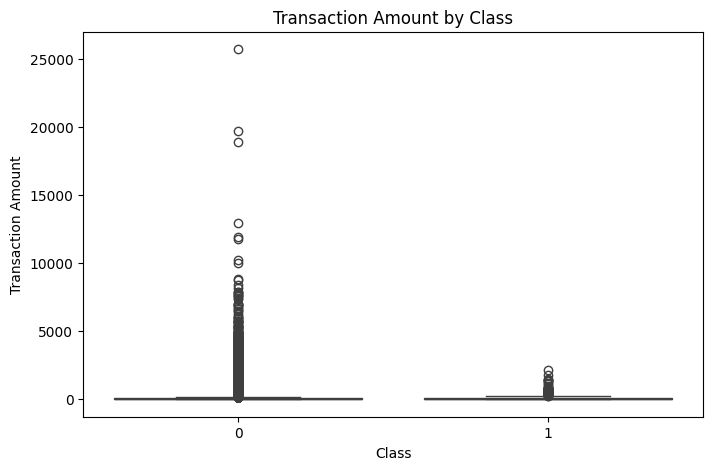

In [22]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)
plt.title("Transaction Amount by Class")
plt.xlabel("Class")
plt.ylabel("Transaction Amount")

plt.show()

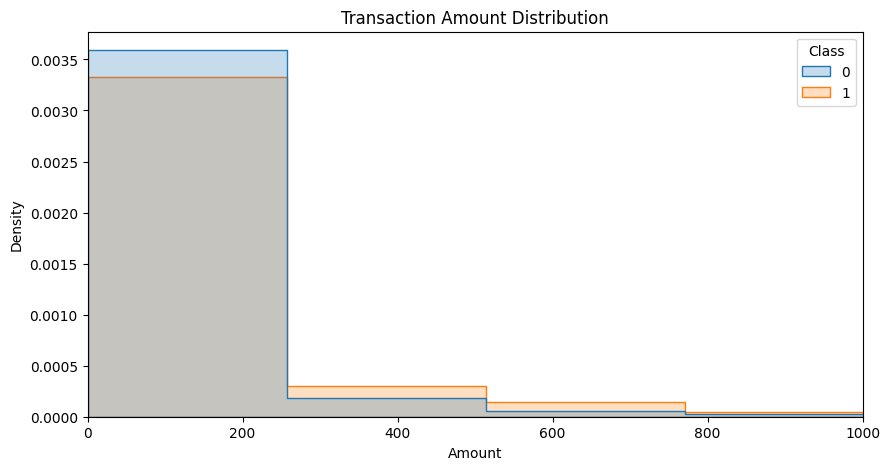

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(0, 1000)

plt.title("Transaction Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Density")

plt.show()

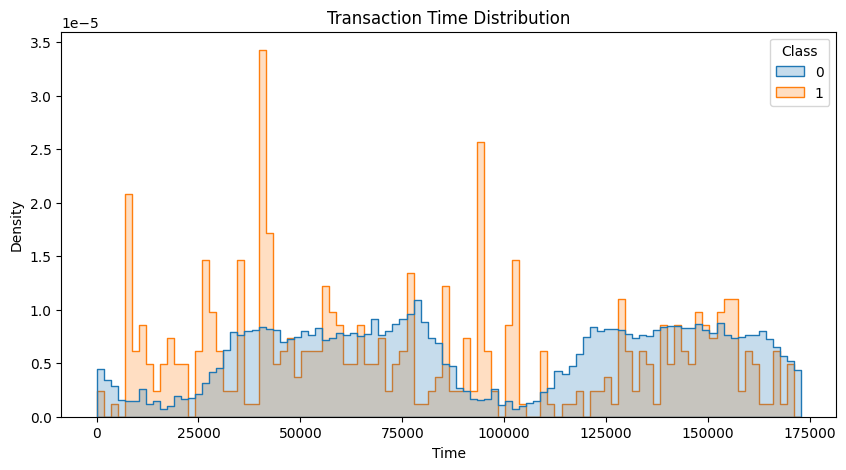

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Time Distribution")
plt.xlabel("Time")
plt.ylabel("Density")

plt.show()

## 5. Correlation Analysis

A correlation matrix is generated to examine the relationships among the numerical variables and the target variable.

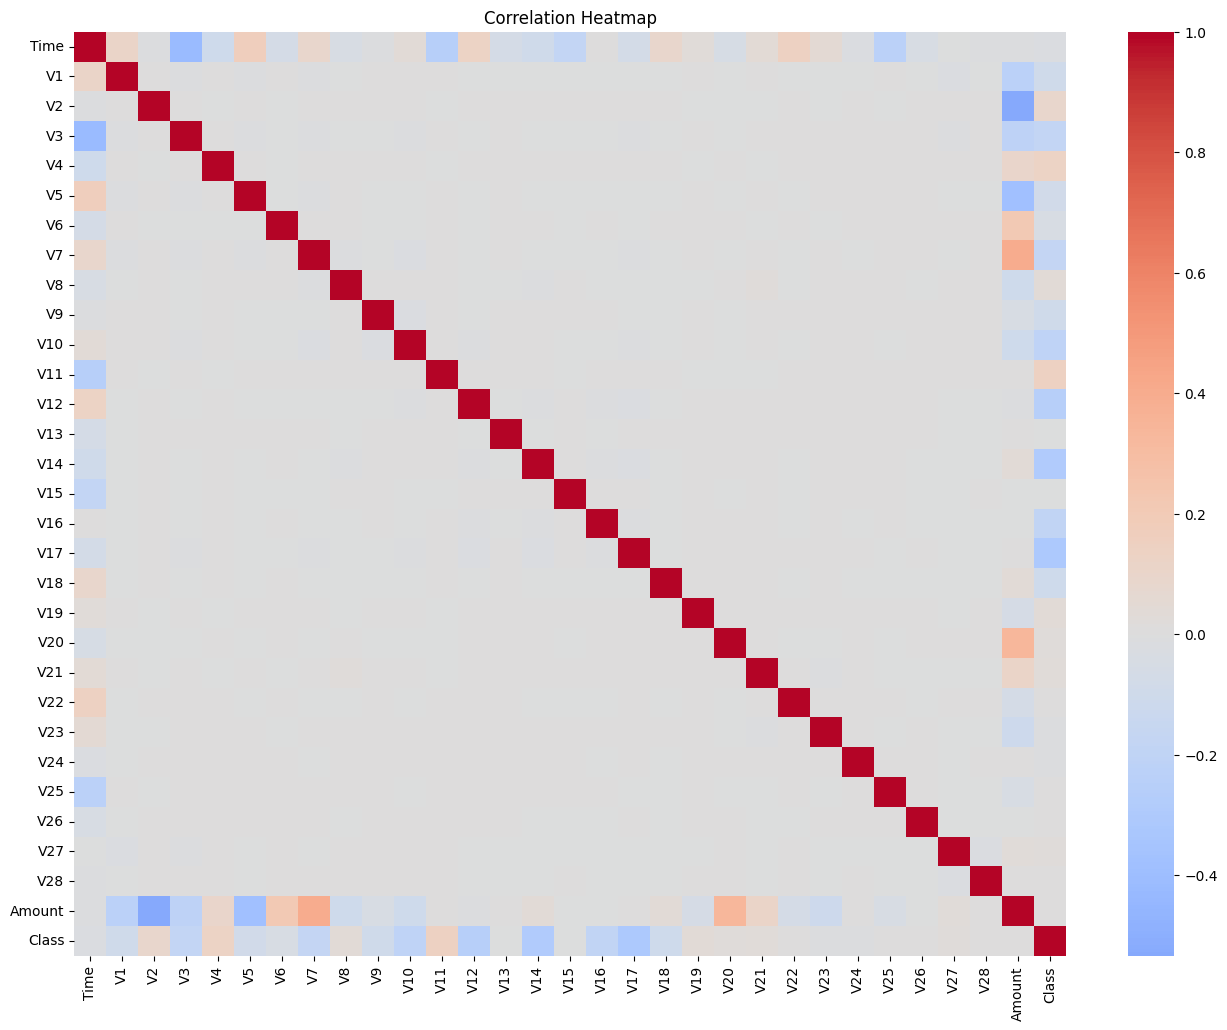

In [25]:
plt.figure(figsize=(16, 12))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")

plt.show()

In [26]:
class_correlation = (
    df.corr()["Class"]
    .drop("Class")
    .sort_values()
)

print(class_correlation)

V17      -0.313498
V14      -0.293375
V12      -0.250711
V10      -0.206971
V16      -0.187186
V3       -0.182322
V7       -0.172347
V18      -0.105340
V1       -0.094486
V9       -0.094021
V5       -0.087812
V6       -0.043915
Time     -0.012359
V24      -0.007210
V23      -0.006333
V13      -0.003897
V15      -0.003300
V25       0.003202
V26       0.004265
V22       0.004887
Amount    0.005777
V28       0.009682
V20       0.021486
V27       0.021892
V21       0.026357
V8        0.033068
V19       0.033631
V2        0.084624
V4        0.129326
V11       0.149067
Name: Class, dtype: float64


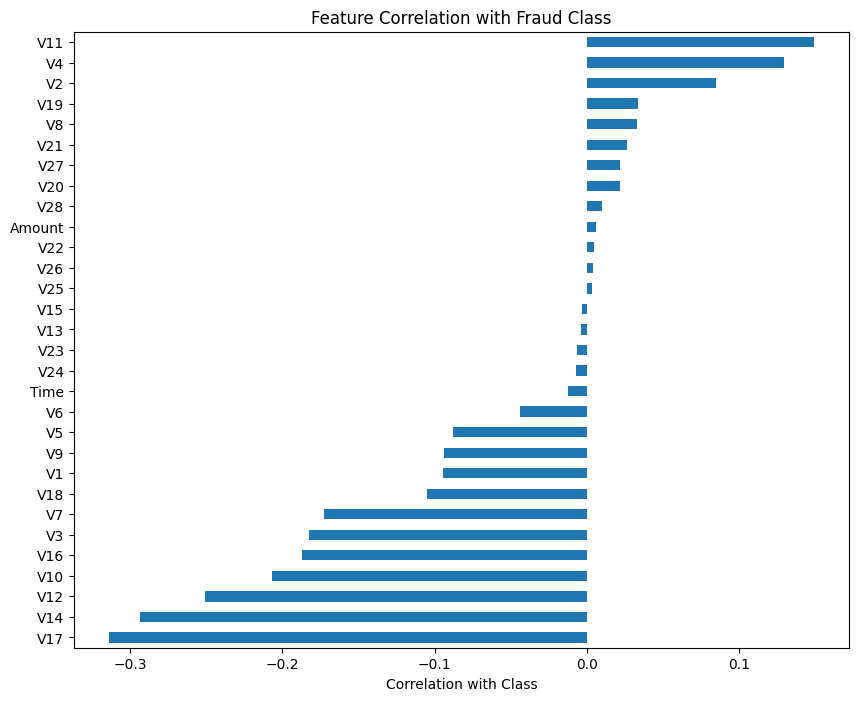

In [27]:
plt.figure(figsize=(10, 8))

class_correlation.plot(kind="barh")

plt.title("Feature Correlation with Fraud Class")
plt.xlabel("Correlation with Class")

plt.show()

## 6. Feature and Target Separation

The `Class` column is used as the target variable. All remaining columns are used as input features.

In [28]:
# Features
X = df.drop("Class", axis=1)

# Target
y = df["Class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (283726, 30)
Target shape: (283726,)


## 7. Train-Test Split

The dataset is divided into training and testing subsets using an 80:20 ratio. Stratified sampling is used so that the highly imbalanced fraud-to-legitimate transaction ratio is preserved in both subsets.

In [29]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training set: (226980, 30)
Testing set : (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [30]:
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit scaler only on training data
X_train_scaled[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

# Apply the same scaler to test data
X_test_scaled[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("Scaling completed successfully.")

Scaling completed successfully.


# 8. Logistic Regression

Logistic Regression is used as the baseline classification model. Because the dataset is highly imbalanced, `class_weight="balanced"` is used to give greater importance to the minority fraud class.

In [31]:
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [32]:
y_pred_lr = logistic_model.predict(X_test_scaled)

y_prob_lr = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

In [33]:
print("Logistic Regression")
print("=" * 50)

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_lr))
print("PR-AUC   :", average_precision_score(y_test, y_prob_lr))

Logistic Regression
Accuracy : 0.9752405455891164
Precision: 0.05623306233062331
Recall   : 0.8736842105263158
F1 Score : 0.10566518141311267
ROC-AUC  : 0.9658392242808925
PR-AUC   : 0.6719353631354262


In [34]:
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Legitimate", "Fraud"]
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56651
       Fraud       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



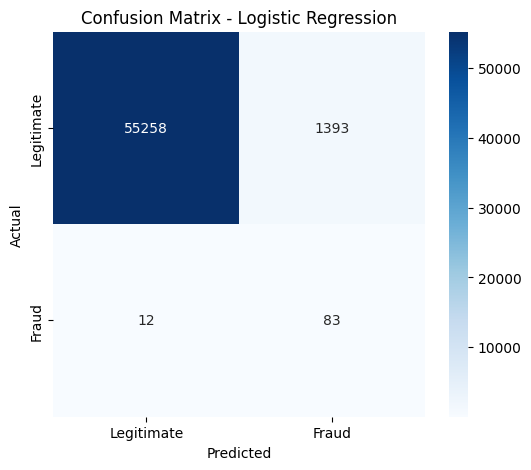

In [35]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

# 9. Decision Tree

A Decision Tree classifier is implemented because it is one of the primary techniques investigated in the reference paper. Class weighting is used to address the class imbalance.

In [36]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=8,
    class_weight="balanced",
    random_state=42
)

decision_tree_model.fit(
    X_train,
    y_train
)

print("Decision Tree training completed.")

Decision Tree training completed.


In [37]:
y_pred_dt = decision_tree_model.predict(X_test)

y_prob_dt = decision_tree_model.predict_proba(
    X_test
)[:, 1]

In [38]:
print("Decision Tree")
print("=" * 50)

print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall   :", recall_score(y_test, y_pred_dt))
print("F1 Score :", f1_score(y_test, y_pred_dt))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_dt))
print("PR-AUC   :", average_precision_score(y_test, y_prob_dt))

Decision Tree
Accuracy : 0.9914707644591689
Precision: 0.14048059149722736
Recall   : 0.8
F1 Score : 0.2389937106918239
ROC-AUC  : 0.9073839919209863
PR-AUC   : 0.49250862063972195


# 10. Random Forest

Random Forest is an ensemble learning method that combines multiple decision trees. It is used as an extension of the single Decision Tree approach.

In [39]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest training completed.")

Random Forest training completed.


In [40]:
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(
    X_test
)[:, 1]

In [41]:
print("Random Forest")
print("=" * 50)

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_rf))
print("PR-AUC   :", average_precision_score(y_test, y_prob_rf))

Random Forest
Accuracy : 0.9994889507630493
Precision: 0.9583333333333334
Recall   : 0.7263157894736842
F1 Score : 0.8263473053892215
ROC-AUC  : 0.947420076200634
PR-AUC   : 0.8033339313357926


# 11. SMOTE-Based Random Forest

The Synthetic Minority Over-sampling Technique (SMOTE) is applied only to the training dataset. The test dataset remains untouched so that evaluation represents performance on the original class distribution.

In [42]:
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Original training shape:", X_train.shape)
print("SMOTE training shape   :", X_train_smote.shape)

print("\nOriginal training distribution:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Original training shape: (226980, 30)
SMOTE training shape   : (453204, 30)

Original training distribution:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64


In [45]:
smote_rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

smote_rf_model.fit(
    X_train_smote,
    y_train_smote
)

print("SMOTE + Random Forest training completed.")

SMOTE + Random Forest training completed.


In [46]:
y_pred_smote_rf = smote_rf_model.predict(X_test)

y_prob_smote_rf = smote_rf_model.predict_proba(
    X_test
)[:, 1]

In [47]:
print("SMOTE + Random Forest")
print("=" * 50)

print("Accuracy :", accuracy_score(y_test, y_pred_smote_rf))
print("Precision:", precision_score(y_test, y_pred_smote_rf))
print("Recall   :", recall_score(y_test, y_pred_smote_rf))
print("F1 Score :", f1_score(y_test, y_pred_smote_rf))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_smote_rf))
print("PR-AUC   :", average_precision_score(y_test, y_prob_smote_rf))

SMOTE + Random Forest
Accuracy : 0.9994360836006062
Precision: 0.8795180722891566
Recall   : 0.7684210526315789
F1 Score : 0.8202247191011236
ROC-AUC  : 0.9690106273963668
PR-AUC   : 0.8090798930383585


# 12. Balanced Random Forest

Balanced Random Forest is an ensemble technique designed to address class imbalance during tree construction. It is included as an additional imbalance-aware model.

In [48]:
balanced_rf_model = BalancedRandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

balanced_rf_model.fit(
    X_train,
    y_train
)

print("Balanced Random Forest training completed.")

Balanced Random Forest training completed.


In [49]:
y_pred_brf = balanced_rf_model.predict(X_test)

y_prob_brf = balanced_rf_model.predict_proba(
    X_test
)[:, 1]

In [50]:
print("Balanced Random Forest")
print("=" * 50)

print("Accuracy :", accuracy_score(y_test, y_pred_brf))
print("Precision:", precision_score(y_test, y_pred_brf))
print("Recall   :", recall_score(y_test, y_pred_brf))
print("F1 Score :", f1_score(y_test, y_pred_brf))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_brf))
print("PR-AUC   :", average_precision_score(y_test, y_prob_brf))

Balanced Random Forest
Accuracy : 0.9878757974130336
Precision: 0.1051930758988016
Recall   : 0.8315789473684211
F1 Score : 0.1867612293144208
ROC-AUC  : 0.9727071292465689
PR-AUC   : 0.7174615616597755


# 13. XGBoost

XGBoost is an advanced gradient boosting algorithm. It is included to investigate whether a boosting-based ensemble can improve fraud detection compared with the classical models and Random Forest approaches.

In [51]:
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative class:", negative_count)
print("Positive class:", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Negative class: 226602
Positive class: 378
Scale Pos Weight: 599.4761904761905


In [52]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

XGBoost training completed.


In [53]:
y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(
    X_test
)[:, 1]

In [54]:
print("XGBoost")
print("=" * 50)

print("Accuracy :", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall   :", recall_score(y_test, y_pred_xgb))
print("F1 Score :", f1_score(y_test, y_pred_xgb))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_xgb))
print("PR-AUC   :", average_precision_score(y_test, y_prob_xgb))

XGBoost
Accuracy : 0.9994713283755683
Precision: 0.8735632183908046
Recall   : 0.8
F1 Score : 0.8351648351648352
ROC-AUC  : 0.9768911962347485
PR-AUC   : 0.8130232794358793


# 14. Model Performance Comparison

The performance of all implemented models is compared using accuracy, precision, recall, F1-score, ROC-AUC and PR-AUC.

In [55]:
results = []

models = [
    ("Logistic Regression", y_pred_lr, y_prob_lr),
    ("Decision Tree", y_pred_dt, y_prob_dt),
    ("Random Forest", y_pred_rf, y_prob_rf),
    ("SMOTE + Random Forest", y_pred_smote_rf, y_prob_smote_rf),
    ("Balanced Random Forest", y_pred_brf, y_prob_brf),
    ("XGBoost", y_pred_xgb, y_prob_xgb)
]

for name, predictions, probabilities in models:

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.975241,0.056233,0.873684,0.105665,0.965839,0.671935
1,Decision Tree,0.991471,0.140481,0.800000,0.238994,0.907384,0.492509
2,Random Forest,0.999489,0.958333,0.726316,0.826347,0.947420,0.803334
3,SMOTE + Random Forest,0.999436,0.879518,0.768421,0.820225,0.969011,0.809080
4,Balanced Random Forest,0.987876,0.105193,0.831579,0.186761,0.972707,0.717462
5,XGBoost,0.999471,0.873563,0.800000,0.835165,0.976891,0.813023


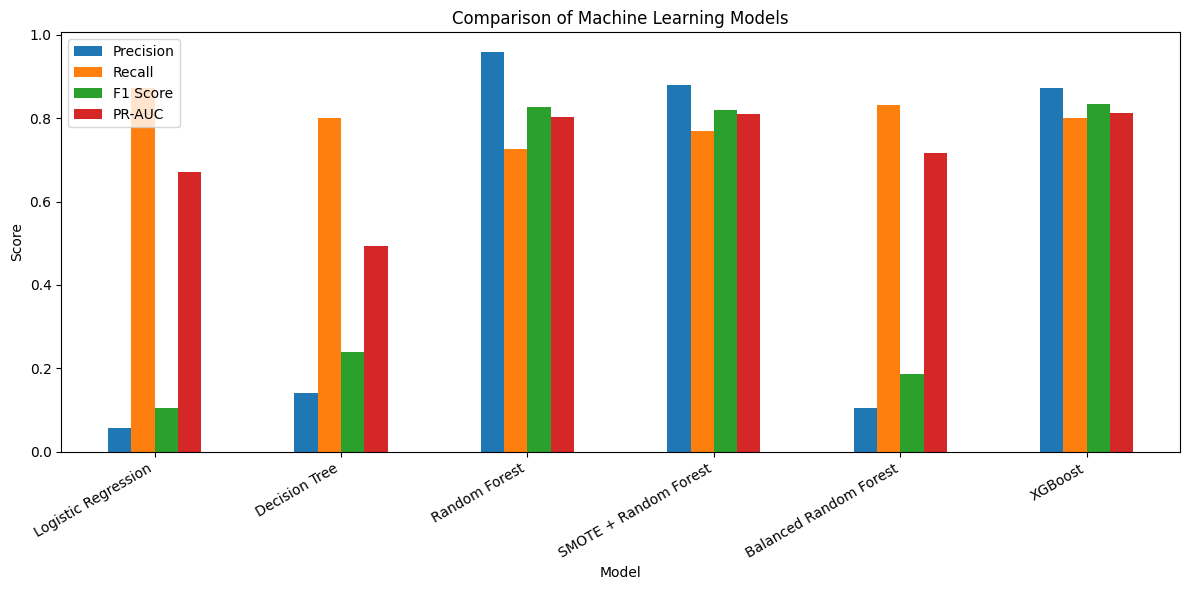

In [56]:
metrics_to_plot = [
    "Precision",
    "Recall",
    "F1 Score",
    "PR-AUC"
]

results_plot = results_df.set_index("Model")[metrics_to_plot]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()

plt.show()

# 15. Confusion Matrix Analysis

The confusion matrix is used to examine the number of correctly and incorrectly classified legitimate and fraudulent transactions.

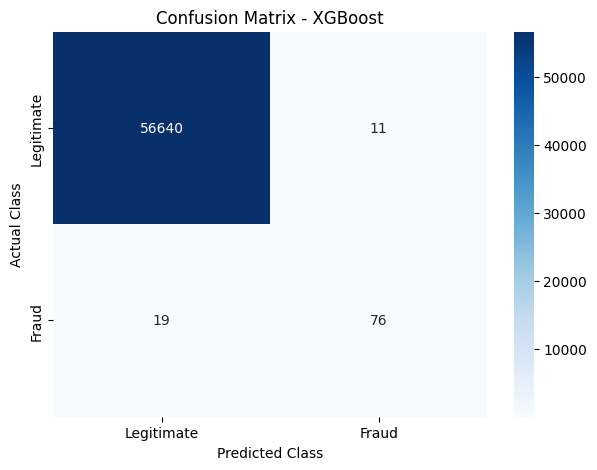

In [57]:
cm_xgb = confusion_matrix(
    y_test,
    y_pred_xgb
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - XGBoost")

plt.show()

# 16. ROC Curve Comparison

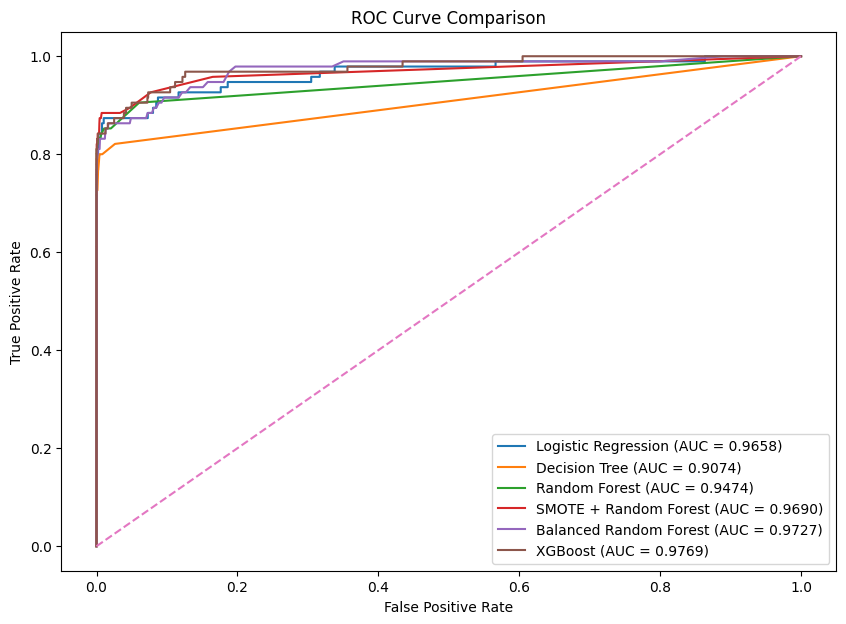

In [58]:
model_probabilities = {
    "Logistic Regression": y_prob_lr,
    "Decision Tree": y_prob_dt,
    "Random Forest": y_prob_rf,
    "SMOTE + Random Forest": y_prob_smote_rf,
    "Balanced Random Forest": y_prob_brf,
    "XGBoost": y_prob_xgb
}

plt.figure(figsize=(10, 7))

for name, probabilities in model_probabilities.items():

    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities
    )

    auc_score = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

# 17. Precision-Recall Curve Comparison

Because fraudulent transactions represent only a very small proportion of the dataset, Precision-Recall analysis provides an important complementary evaluation to ROC-AUC.

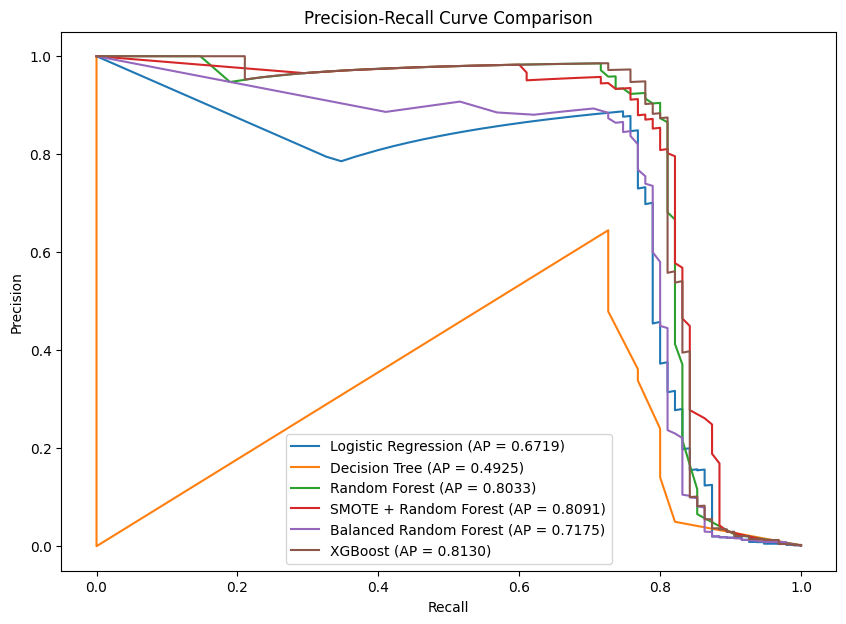

In [59]:
plt.figure(figsize=(10, 7))

for name, probabilities in model_probabilities.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    ap_score = average_precision_score(
        y_test,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap_score:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")

plt.legend()
plt.show()

# 18. Classification Threshold Optimization

The default classification threshold of 0.5 is evaluated against alternative thresholds to study the trade-off between precision and recall.

In [60]:
thresholds = np.arange(
    0.10,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        y_prob_xgb >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_df = pd.DataFrame(
    threshold_results
)

threshold_df

,Threshold,Precision,Recall,F1 Score
0,0.10,0.509677,0.831579,0.632000
1,0.15,0.601562,0.810526,0.690583
2,0.20,0.669565,0.810526,0.733333
3,0.25,0.719626,0.810526,0.762376
4,0.30,0.754902,0.810526,0.781726
5,0.35,0.777778,0.810526,0.793814
6,0.40,0.819149,0.810526,0.814815
7,0.45,0.873563,0.800000,0.835165
8,0.50,0.873563,0.800000,0.835165
9,0.55,0.883721,0.800000,0.839779


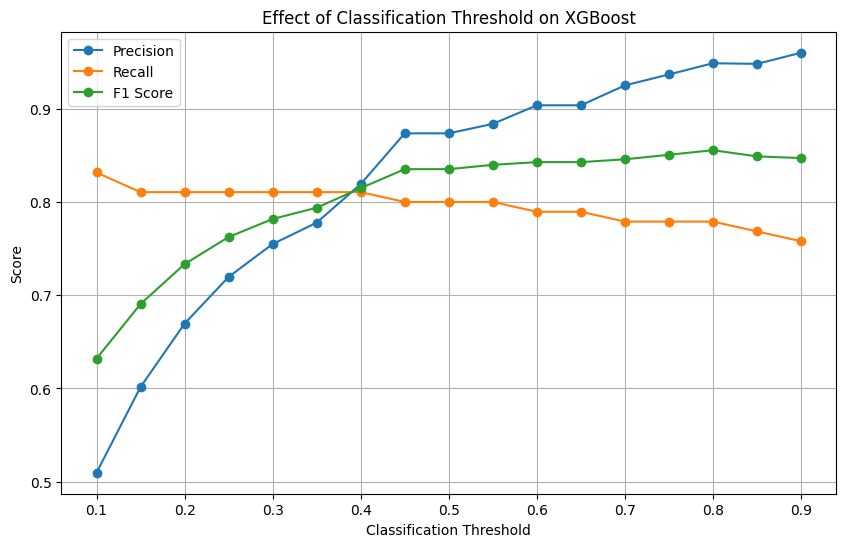

In [61]:
plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Effect of Classification Threshold on XGBoost")
plt.legend()

plt.grid(True)
plt.show()

In [62]:
best_threshold_row = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

print("Best threshold based on F1-score:")
print(best_threshold_row)

Best threshold based on F1-score:
Threshold    0.800000
Precision    0.948718
Recall       0.778947
F1 Score     0.855491
Name: 14, dtype: float64


# 19. Feature Importance

Feature importance is analyzed using the trained XGBoost model to identify the input variables that contribute most strongly to the model's predictions.

In [63]:
feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

feature_importance.head(10)

V14    0.419869
V10    0.064234
V4     0.054980
V12    0.042649
V19    0.035125
V8     0.034511
V20    0.030771
V13    0.025124
V3     0.019999
V26    0.019643
dtype: float32

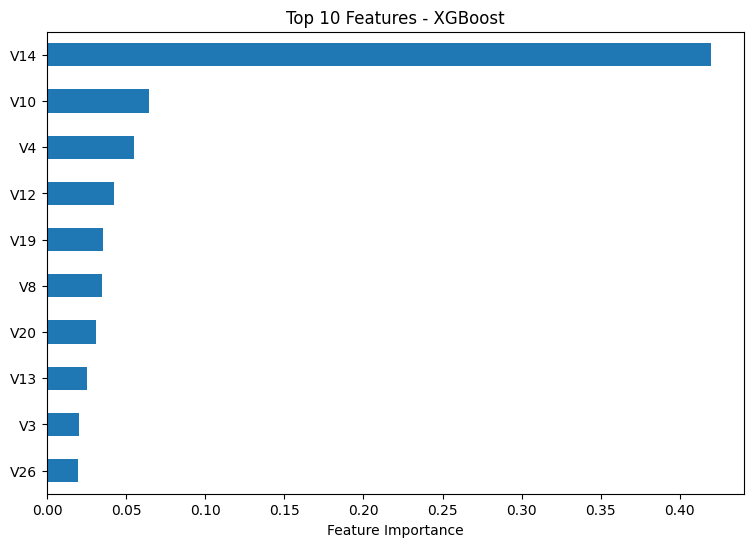

In [64]:
plt.figure(figsize=(9, 6))

feature_importance.head(10).sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Features - XGBoost")
plt.xlabel("Feature Importance")

plt.show()

In [65]:
from sklearn.model_selection import RandomizedSearchCV

In [66]:
param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [3, 4, 5, 6, 7],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

In [67]:
xgb_for_tuning = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [68]:
random_search = RandomizedSearchCV(
    estimator=xgb_for_tuning,
    param_distributions=param_grid,
    n_iter=15,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [69]:
random_search.fit(
    X_train,
    y_train
)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], 'n_estimators': [100, 200, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a

In [70]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

Best Parameters:
{'subsample': 1.0, 'n_estimators': 400, 'max_depth': 7, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

Best Cross-Validation PR-AUC:
0.8537839927697698


In [71]:
best_xgb_model = random_search.best_estimator_

y_pred_tuned_xgb = best_xgb_model.predict(
    X_test
)

y_prob_tuned_xgb = best_xgb_model.predict_proba(
    X_test
)[:, 1]

In [72]:
print("Tuned XGBoost")
print("=" * 50)

print(
    "Accuracy :",
    accuracy_score(y_test, y_pred_tuned_xgb)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_tuned_xgb)
)

print(
    "Recall   :",
    recall_score(y_test, y_pred_tuned_xgb)
)

print(
    "F1 Score :",
    f1_score(y_test, y_pred_tuned_xgb)
)

print(
    "ROC-AUC  :",
    roc_auc_score(y_test, y_prob_tuned_xgb)
)

print(
    "PR-AUC   :",
    average_precision_score(
        y_test,
        y_prob_tuned_xgb
    )
)

Tuned XGBoost
Accuracy : 0.9995241955380115
Precision: 0.9358974358974359
Recall   : 0.7684210526315789
F1 Score : 0.8439306358381503
ROC-AUC  : 0.9767886291782836
PR-AUC   : 0.8218781146554155


In [73]:
tuned_result = pd.DataFrame([{
    "Model": "Tuned XGBoost",
    "Accuracy": accuracy_score(
        y_test,
        y_pred_tuned_xgb
    ),
    "Precision": precision_score(
        y_test,
        y_pred_tuned_xgb
    ),
    "Recall": recall_score(
        y_test,
        y_pred_tuned_xgb
    ),
    "F1 Score": f1_score(
        y_test,
        y_pred_tuned_xgb
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        y_prob_tuned_xgb
    ),
    "PR-AUC": average_precision_score(
        y_test,
        y_prob_tuned_xgb
    )
}])

final_results_df = pd.concat(
    [results_df, tuned_result],
    ignore_index=True
)

final_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9752,0.0562,0.8737,0.1057,0.9658,0.6719
1,Decision Tree,0.9915,0.1405,0.8000,0.2390,0.9074,0.4925
2,Random Forest,0.9995,0.9583,0.7263,0.8263,0.9474,0.8033
3,SMOTE + Random Forest,0.9994,0.8795,0.7684,0.8202,0.9690,0.8091
4,Balanced Random Forest,0.9879,0.1052,0.8316,0.1868,0.9727,0.7175
5,XGBoost,0.9995,0.8736,0.8000,0.8352,0.9769,0.8130
6,Tuned XGBoost,0.9995,0.9359,0.7684,0.8439,0.9768,0.8219


In [74]:
final_results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

threshold_df.to_csv(
    "threshold_analysis.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


## Overfitting Analysis – Train vs Test Performance

In [75]:
# Display variables currently available in the notebook
%whos

Variable                         Type                              Data/Info
----------------------------------------------------------------------------
BalancedRandomForestClassifier   ABCMeta                           <class 'imblearn.ensemble<...>dRandomForestClassifier'>
DecisionTreeClassifier           ABCMeta                           <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
LogisticRegression               type                              <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
RandomForestClassifier           ABCMeta                           <class 'sklearn.ensemble.<...>.RandomForestClassifier'>
RandomizedSearchCV               ABCMeta                           <class 'sklearn.model_sel<...>arch.RandomizedSearchCV'>
SMOTE                            ABCMeta                           <class 'imblearn.over_sam<...>pling._smote.base.SMOTE'>
StandardScaler                   type                              <class 'sklearn.preproces<...>ng._data.St

In [79]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "SMOTE + Random Forest": smote,
    "Balanced Random Forest": balanced_rf_model,
    "XGBoost": xgb_model,
    "Tuned XGBoost": xgb_for_tuning
}

In [80]:
from sklearn.metrics import f1_score, average_precision_score
import pandas as pd
import numpy as np

results = []

for name, model in models.items():

    # --------------------------------------------------
    # TRAIN SET PREDICTIONS
    # --------------------------------------------------
    y_train_pred = model.predict(X_train)

    # --------------------------------------------------
    # TEST SET PREDICTIONS
    # --------------------------------------------------
    y_test_pred = model.predict(X_test)

    # --------------------------------------------------
    # F1-SCORE
    # --------------------------------------------------
    train_f1 = f1_score(y_train, y_train_pred)
    test_f1 = f1_score(y_test, y_test_pred)

    # --------------------------------------------------
    # PROBABILITY SCORES FOR PR-AUC
    # --------------------------------------------------
    if hasattr(model, "predict_proba"):
        y_train_prob = model.predict_proba(X_train)[:, 1]
        y_test_prob = model.predict_proba(X_test)[:, 1]

    elif hasattr(model, "decision_function"):
        y_train_prob = model.decision_function(X_train)
        y_test_prob = model.decision_function(X_test)

    else:
        print(f"Skipping PR-AUC for {name}: no probability/decision scores available.")
        continue

    # --------------------------------------------------
    # PR-AUC
    # --------------------------------------------------
    train_pr_auc = average_precision_score(y_train, y_train_prob)
    test_pr_auc = average_precision_score(y_test, y_test_prob)

    # --------------------------------------------------
    # TRAIN-TEST GAPS
    # --------------------------------------------------
    f1_gap = train_f1 - test_f1
    pr_auc_gap = train_pr_auc - test_pr_auc

    # --------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------
    results.append({
        "Model": name,
        "Train F1": train_f1,
        "Test F1": test_f1,
        "F1 Gap": f1_gap,
        "Train PR-AUC": train_pr_auc,
        "Test PR-AUC": test_pr_auc,
        "PR-AUC Gap": pr_auc_gap
    })


# Convert results into DataFrame
overfitting_results = pd.DataFrame(results)

# Display results
overfitting_results

AttributeError: 'SMOTE' object has no attribute 'predict'

In [1]:
print("Checking trained models...")

variables_to_check = [
    "log_reg",
    "dt_model",
    "rf_model",
    "rf_smote",
    "balanced_rf",
    "xgb_model",
    "tuned_xgb"
]

for var in variables_to_check:
    if var in globals():
        print(f"{var}: {type(globals()[var]).__name__}")
    else:
        print(f"{var}: NOT FOUND")

Checking trained models...
log_reg: NOT FOUND
dt_model: NOT FOUND
rf_model: NOT FOUND
rf_smote: NOT FOUND
balanced_rf: NOT FOUND
xgb_model: NOT FOUND
tuned_xgb: NOT FOUND


In [2]:
%whos

Variable             Type    Data/Info
--------------------------------------
var                  str     tuned_xgb
variables_to_check   list    n=7


In [4]:
# ============================================================
# STEP 1 — LOAD DATA AND PREPARE FEATURES
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from xgboost import XGBClassifier

# Load dataset
df = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

# Features and target
X = df.drop("Class", axis=1)
y = df["Class"]

print("\nFeatures:", X.shape)
print("Target:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nClass distribution:")
print(y.value_counts())

Dataset loaded successfully.
Shape: (284807, 31)

Features: (284807, 30)
Target: (284807,)

Feature columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [5]:
# ============================================================
# STEP 2 — RECREATE THE ORIGINAL TRAIN/TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train/Test split completed.")

print("\nTraining set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Train/Test split completed.

Training set:
X_train: (227845, 30)
y_train: (227845,)

Testing set:
X_test: (56962, 30)
y_test: (56962,)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [6]:
scale_pos_weight=scale_pos_weight


NameError: name 'scale_pos_weight' is not defined

In [7]:
# ============================================================
# STEP 3 — CALCULATE SCALE_POS_WEIGHT
# ============================================================

scale_pos_weight = (
    y_train.value_counts()[0] /
    y_train.value_counts()[1]
)

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 577.2868020304569


In [8]:
# ============================================================
# STEP 4 — RECREATE XGBOOST TUNING CONFIGURATION
# ============================================================

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

# Base XGBoost model used for hyperparameter tuning
xgb_for_tuning = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter search space
param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [3, 4, 5, 6, 7],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

print("XGBoost tuning configuration recreated successfully.")
print("\nSearch space:")
print(param_grid)

XGBoost tuning configuration recreated successfully.

Search space:
{'n_estimators': [100, 200, 300, 400], 'max_depth': [3, 4, 5, 6, 7], 'learning_rate': [0.01, 0.03, 0.05, 0.1], 'subsample': [0.7, 0.8, 0.9, 1.0], 'colsample_bytree': [0.7, 0.8, 0.9, 1.0]}


In [9]:
# ============================================================
# STEP 5 — RUN RANDOMIZED SEARCH
# ============================================================

random_search = RandomizedSearchCV(
    estimator=xgb_for_tuning,
    param_distributions=param_grid,
    n_iter=15,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Starting RandomizedSearchCV...")
print("15 parameter combinations × 3-fold CV = 45 model fits.")
print()

random_search.fit(
    X_train,
    y_train
)

print("\nRandomizedSearchCV completed successfully.")

Starting RandomizedSearchCV...
15 parameter combinations × 3-fold CV = 45 model fits.

Fitting 3 folds for each of 15 candidates, totalling 45 fits

RandomizedSearchCV completed successfully.


In [10]:
# ============================================================
# STEP 6 — RECOVER AND EVALUATE BEST TUNED XGBOOST
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Get the best model selected by RandomizedSearchCV
best_xgb_model = random_search.best_estimator_

# Best hyperparameters
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

# Test predictions
y_pred_tuned_xgb = best_xgb_model.predict(X_test)

# Fraud probabilities
y_prob_tuned_xgb = best_xgb_model.predict_proba(X_test)[:, 1]

# Test metrics
accuracy = accuracy_score(y_test, y_pred_tuned_xgb)
precision = precision_score(y_test, y_pred_tuned_xgb)
recall = recall_score(y_test, y_pred_tuned_xgb)
f1 = f1_score(y_test, y_pred_tuned_xgb)
roc_auc = roc_auc_score(y_test, y_prob_tuned_xgb)
pr_auc = average_precision_score(y_test, y_prob_tuned_xgb)

print("\n" + "=" * 55)
print("TUNED XGBOOST — TEST RESULTS")
print("=" * 55)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall   : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score : {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC-AUC  : {roc_auc:.4f} ({roc_auc*100:.2f}%)")
print(f"PR-AUC   : {pr_auc:.4f} ({pr_auc*100:.2f}%)")

Best Parameters:
{'subsample': 0.7, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}

Best Cross-Validation PR-AUC:
0.8430919908832376

TUNED XGBOOST — TEST RESULTS
Accuracy : 0.9995 (99.95%)
Precision: 0.8710 (87.10%)
Recall   : 0.8265 (82.65%)
F1 Score : 0.8482 (84.82%)
ROC-AUC  : 0.9857 (98.57%)
PR-AUC   : 0.8721 (87.21%)


In [11]:
print("Threshold analysis:")
display(pd.read_csv("threshold_analysis.csv"))

Threshold analysis:


,Threshold,Precision,Recall,F1 Score
0,0.10,0.509677,0.831579,0.632000
1,0.15,0.601562,0.810526,0.690583
2,0.20,0.669565,0.810526,0.733333
3,0.25,0.719626,0.810526,0.762376
4,0.30,0.754902,0.810526,0.781726
5,0.35,0.777778,0.810526,0.793814
6,0.40,0.819149,0.810526,0.814815
7,0.45,0.873563,0.800000,0.835165
8,0.50,0.873563,0.800000,0.835165
9,0.55,0.883721,0.800000,0.839779


In [12]:
threshold_df = pd.read_csv("threshold_analysis.csv")

print(threshold_df)

    Threshold  Precision    Recall  F1 Score
0        0.10   0.509677  0.831579  0.632000
1        0.15   0.601562  0.810526  0.690583
2        0.20   0.669565  0.810526  0.733333
3        0.25   0.719626  0.810526  0.762376
4        0.30   0.754902  0.810526  0.781726
5        0.35   0.777778  0.810526  0.793814
6        0.40   0.819149  0.810526  0.814815
7        0.45   0.873563  0.800000  0.835165
8        0.50   0.873563  0.800000  0.835165
9        0.55   0.883721  0.800000  0.839779
10       0.60   0.903614  0.789474  0.842697
11       0.65   0.903614  0.789474  0.842697
12       0.70   0.925000  0.778947  0.845714
13       0.75   0.936709  0.778947  0.850575
14       0.80   0.948718  0.778947  0.855491
15       0.85   0.948052  0.768421  0.848837
16       0.90   0.960000  0.757895  0.847059


In [13]:
# ============================================================
# STEP 7 — VERIFY THRESHOLD PERFORMANCE
# ============================================================

from sklearn.metrics import precision_score, recall_score, f1_score

threshold = 0.80

y_pred_threshold = (y_prob_tuned_xgb >= threshold).astype(int)

threshold_precision = precision_score(y_test, y_pred_threshold)
threshold_recall = recall_score(y_test, y_pred_threshold)
threshold_f1 = f1_score(y_test, y_pred_threshold)

print("=" * 55)
print(f"TUNED XGBOOST — THRESHOLD = {threshold}")
print("=" * 55)

print(f"Precision: {threshold_precision:.4f} ({threshold_precision*100:.2f}%)")
print(f"Recall   : {threshold_recall:.4f} ({threshold_recall*100:.2f}%)")
print(f"F1 Score : {threshold_f1:.4f} ({threshold_f1*100:.2f}%)")

TUNED XGBOOST — THRESHOLD = 0.8
Precision: 0.9091 (90.91%)
Recall   : 0.8163 (81.63%)
F1 Score : 0.8602 (86.02%)


In [14]:
# ============================================================
# STEP 8 — FIND BEST F1 THRESHOLD FOR RECOVERED MODEL
# ============================================================

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob_tuned_xgb >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_df_new = pd.DataFrame(threshold_results)

print(threshold_df_new.to_string(index=False))

# Find threshold with maximum F1
best_threshold_row = threshold_df_new.loc[
    threshold_df_new["F1 Score"].idxmax()
]

print("\n" + "=" * 55)
print("BEST THRESHOLD FOR RECOVERED MODEL")
print("=" * 55)

print(
    f"Threshold : {best_threshold_row['Threshold']:.2f}"
)

print(
    f"Precision : {best_threshold_row['Precision']:.4f}"
)

print(
    f"Recall    : {best_threshold_row['Recall']:.4f}"
)

print(
    f"F1 Score  : {best_threshold_row['F1 Score']:.4f}"
)

 Threshold  Precision   Recall  F1 Score
      0.10   0.770642 0.857143  0.811594
      0.15   0.821782 0.846939  0.834171
      0.20   0.846939 0.846939  0.846939
      0.25   0.846939 0.846939  0.846939
      0.30   0.846939 0.846939  0.846939
      0.35   0.864583 0.846939  0.855670
      0.40   0.873684 0.846939  0.860104
      0.45   0.870968 0.826531  0.848168
      0.50   0.870968 0.826531  0.848168
      0.55   0.890110 0.826531  0.857143
      0.60   0.890110 0.826531  0.857143
      0.65   0.890110 0.826531  0.857143
      0.70   0.890110 0.826531  0.857143
      0.75   0.909091 0.816327  0.860215
      0.80   0.909091 0.816327  0.860215
      0.85   0.909091 0.816327  0.860215
      0.90   0.906977 0.795918  0.847826

BEST THRESHOLD FOR RECOVERED MODEL
Threshold : 0.75
Precision : 0.9091
Recall    : 0.8163
F1 Score  : 0.8602


In [15]:
# ============================================================
# STEP 9 — SAVE FINAL MODEL FOR DASHBOARD
# ============================================================

import os
import json
import joblib

# Create models directory
os.makedirs("models", exist_ok=True)

# ------------------------------------------------------------
# 1. Save trained XGBoost model
# ------------------------------------------------------------

model_path = "models/tuned_xgboost.joblib"

joblib.dump(
    best_xgb_model,
    model_path
)

# ------------------------------------------------------------
# 2. Save classification threshold
# ------------------------------------------------------------

best_threshold = float(best_threshold_row["Threshold"])

threshold_info = {
    "threshold": best_threshold,
    "selection_criterion": "Maximum F1 Score",
    "precision": float(best_threshold_row["Precision"]),
    "recall": float(best_threshold_row["Recall"]),
    "f1_score": float(best_threshold_row["F1 Score"])
}

with open("models/threshold.json", "w") as f:
    json.dump(
        threshold_info,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 3. Save feature names and order
# ------------------------------------------------------------

feature_info = {
    "features": X.columns.tolist(),
    "number_of_features": len(X.columns),
    "target": "Class"
}

with open("models/feature_names.json", "w") as f:
    json.dump(
        feature_info,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 4. Display confirmation
# ------------------------------------------------------------

print("=" * 60)
print("MODEL ARTIFACTS SAVED SUCCESSFULLY")
print("=" * 60)

print("\nSaved files:")

print("1.", model_path)
print("2. models/threshold.json")
print("3. models/feature_names.json")

print("\nFinal threshold:", best_threshold)

print("\nModel features:")
print(X.columns.tolist())

MODEL ARTIFACTS SAVED SUCCESSFULLY

Saved files:
1. models/tuned_xgboost.joblib
2. models/threshold.json
3. models/feature_names.json

Final threshold: 0.7500000000000002

Model features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [16]:
# ============================================================
# STEP 10 — VERIFY SAVED MODEL
# ============================================================

import joblib
import json

# Load model
loaded_model = joblib.load(
    "models/tuned_xgboost.joblib"
)

# Load threshold
with open("models/threshold.json", "r") as f:
    loaded_threshold_info = json.load(f)

loaded_threshold = loaded_threshold_info["threshold"]

# Generate probabilities using saved model
loaded_probabilities = loaded_model.predict_proba(
    X_test
)[:, 1]

# Apply saved threshold
loaded_predictions = (
    loaded_probabilities >= loaded_threshold
).astype(int)

print("Saved model loaded successfully.")
print("Saved threshold:", loaded_threshold)

print("\nPrediction verification:")

print(
    "Probabilities identical:",
    np.allclose(
        y_prob_tuned_xgb,
        loaded_probabilities
    )
)

print(
    "Predictions identical:",
    np.array_equal(
        (y_prob_tuned_xgb >= loaded_threshold).astype(int),
        loaded_predictions
    )
)

Saved model loaded successfully.
Saved threshold: 0.7500000000000002

Prediction verification:
Probabilities identical: True
Predictions identical: True
